# `tl.gradient_significance`'s coherence (R̄) vs `astropy.stats.circvar`

Compares astrolabe's directional coherence metric against astropy's reference circular statistic. `tl.gradient_significance` computes the circular mean resultant length R̄ = |mean(exp(i*theta))| (Mardia & Jupp 2000) over per-cell gradient direction angles, excluding near-zero-magnitude gradients whose angle is otherwise a meaningless `arctan2(0,0)=0`. `astropy.stats.circvar` reports `1 - R̄`, so `R̄ = 1 - circvar(angles)` is the identity validated here.


In [1]:
import logging
logging.basicConfig(level=logging.INFO)

import time
import numpy as np
import astrolabe as ab
from astropy.stats import circvar


INFO:astrolabe.pl._theme:Registered bundled Inter font files with matplotlib


INFO:astrolabe.pl._theme:astrolabe plot theme set to 'light'


## Dataset

`ab.datasets.xenium_tiny()` with a small handful of genes to compute gradients for - coherence is a per-gene scalar, so a handful is enough to see the correlation across a spread of coherence values.


In [2]:
mdata = ab.datasets.xenium_tiny()
ab.pipeline.filter_xenium(mdata)
ab.pp.normalize_total(mdata)
ab.pp.log1p(mdata)
ab.tl.spatial_neighbors(mdata)

adata = mdata["xenium"]
genes = list(adata.var_names[:8])

ab.tl.expression_gradient(mdata, keys=genes)
genes


INFO:astrolabe.io._xenium:Reading Xenium run 'outs' from C:\Users\Austin\PycharmProjects\astrolabe\benchmarks\astropy_stats\.astrolabe_cache\datasets\xenium_tiny\outs


C:\Users\Austin\PycharmProjects\astrolabe\astrolabe\io\_xenium.py:870: ExperimentalFeatureWarning: Support for Awkward Arrays is currently experimental. Behavior may change in the future. Please report any issues you may encounter!
  adata.obsm[obsm_key] = ak.Array(
INFO:astrolabe.io._xenium:Loaded 358 cells × 520 features (115 control probes)


INFO:astrolabe.io._xenium:Streaming transcripts from C:\Users\Austin\PycharmProjects\astrolabe\benchmarks\astropy_stats\.astrolabe_cache\datasets\xenium_tiny\outs\transcripts.parquet


INFO:astrolabe.io._xenium:Loaded 20999 transcript detections


INFO:astrolabe.pipeline:filter_xenium: 358 cells × 520 genes


...

INFO:astrolabe.tl._gradient:expression_gradient: 'ADAMTS1' — mean magnitude 0.0051, directional coherence R̄=0.236


INFO:astrolabe.tl._gradient:expression_gradient: 'ADGRE1' — mean magnitude 0.0008, directional coherence R̄=0.361


INFO:astrolabe.tl._gradient:expression_gradient: 'ADGRL4' — mean magnitude 0.0038, directional coherence R̄=0.077


INFO:astrolabe.tl._gradient:expression_gradient: 'AIF1' — mean magnitude 0.0037, directional coherence R̄=0.316


['ACKR1', 'ACTA2', 'ACTG2', 'ADAM28', 'ADAMTS1', 'ADGRE1', 'ADGRL4', 'AIF1']

## Astrolabe: `tl.gradient_significance`


In [3]:
_t0 = time.perf_counter()
ab.tl.gradient_significance(mdata, keys=genes, n_perms=200, random_state=0)
t_astro_s = time.perf_counter() - _t0
print(f"astrolabe runtime: {t_astro_s:.4f}s")
coherence_astro = adata.uns["gradient_significance"]["coherence"]
coherence_astro


INFO:astrolabe.tl._gradient:gradient_significance: permutation 1/200


INFO:astrolabe.tl._gradient:gradient_significance: permutation 21/200


INFO:astrolabe.tl._gradient:gradient_significance: permutation 41/200


INFO:astrolabe.tl._gradient:gradient_significance: permutation 61/200


INFO:astrolabe.tl._gradient:gradient_significance: permutation 81/200


...

INFO:astrolabe.tl._gradient:gradient_significance: permutation 161/200


INFO:astrolabe.tl._gradient:gradient_significance: permutation 181/200


INFO:astrolabe.tl._gradient:gradient_significance: 'AIF1' magnitude=0.0037 (p=0.592) coherence=0.316 (p=0.020)


astrolabe runtime: 1.2509s


key
ACKR1      0.223674
ACTA2      0.119974
ACTG2      0.081054
ADAM28     0.398185
ADAMTS1    0.236461
ADGRE1     0.360642
ADGRL4     0.077136
AIF1       0.316429
Name: coherence, dtype: float64

## Reference: `astropy.stats.circvar` on the same (filtered) gradient vectors

Reads the public `obsm['gradient_{key}']` array astrolabe wrote and replicates its `magnitude > 1e-8` filter before computing angles, since a degenerate zero-magnitude gradient's raw `arctan2` angle is defined-but-meaningless rather than genuinely excluded.


In [4]:
_t0 = time.perf_counter()
coherence_ref = {}
for gene in genes:
    grad = adata.obsm[f"gradient_{gene}"].astype(np.float64)
    magnitude = np.linalg.norm(grad, axis=1)
    valid = magnitude > 1e-8
    angles = np.arctan2(grad[valid, 1], grad[valid, 0])
    coherence_ref[gene] = 1.0 - circvar(angles)
t_ref_s = time.perf_counter() - _t0
print(f"reference runtime: {t_ref_s:.4f}s")

coherence_ref


reference runtime: 0.0015s


{'ACKR1': np.float64(0.22367406322530425),
 'ACTA2': np.float64(0.1199744903039125),
 'ACTG2': np.float64(0.08105433272154361),
 'ADAM28': np.float64(0.3981852382537443),
 'ADAMTS1': np.float64(0.23646133505135636),
 'ADGRE1': np.float64(0.36064189890074694),
 'ADGRL4': np.float64(0.07713607582958959),
 'AIF1': np.float64(0.31642947252199627)}

## Agreement


Pearson r = 1.00000000, max |astrolabe - astropy| = 5.55e-17
Runtime: astrolabe 1.2509s vs astropy 0.0015s (823.9x astrolabe slower) -- not apples-to-apples: astrolabe's call also runs a 200-permutation null the astropy reference doesn't.


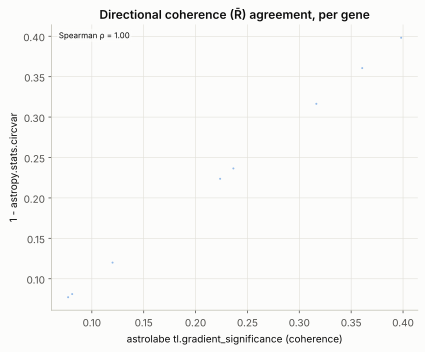

In [5]:
astro_vals = coherence_astro.reindex(genes).to_numpy()
ref_vals = np.array([coherence_ref[g] for g in genes])

r = np.corrcoef(astro_vals, ref_vals)[0, 1]
max_abs_diff = float(np.abs(astro_vals - ref_vals).max())
print(f"Pearson r = {r:.8f}, max |astrolabe - astropy| = {max_abs_diff:.2e}")
print(f"Runtime: astrolabe {t_astro_s:.4f}s vs astropy {t_ref_s:.4f}s "
      f"({max(t_astro_s, t_ref_s) / min(t_astro_s, t_ref_s):.1f}x astrolabe {'faster' if t_astro_s < t_ref_s else 'slower'}) -- "
      f"not apples-to-apples: astrolabe's call also runs a 200-permutation null the astropy reference doesn't.")

panel = ab.pl.scatter(
    adata, x=astro_vals, y=ref_vals, annotate_corr=True,
    xlabel="astrolabe tl.gradient_significance (coherence)", ylabel="1 - astropy.stats.circvar",
    title="Directional coherence (R̄) agreement, per gene",
)
panel.show()


## Interpretation

Both compute the same closed-form statistic on the same filtered angle set, so a near-zero max absolute difference is expected. This mainly guards against the near-zero-magnitude filter or astropy's `1 - circvar` sign convention silently drifting from what `gradient_significance` actually does.
